In [1]:

from pathlib import Path
import pandas as pd
import rasterio

ROOT = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

RASTERS = ROOT / "results" / "rasters"
MANIFEST = ROOT / "results" / "tables" / "ee_export_task_manifest.csv"

tasks = pd.read_csv(MANIFEST)

report = []

for _, row in tasks.iterrows():
    path = RASTERS / row["expected_filename"]

    info = {
        "filename": path.name,
        "exists": path.exists(),
        "readable": False,
        "crs": None,
        "valid_pixels": 0
    }

    if path.exists():
        try:
            with rasterio.open(path) as src:
                info["readable"] = True
                info["crs"] = str(src.crs)
                info["valid_pixels"] = int(
                    src.dataset_mask().astype(bool).sum()
                )
        except Exception as exc:
            print(f"Cannot read {path.name}: {exc}")

    report.append(info)

report = pd.DataFrame(report)

display(report)

print("Expected:", len(tasks))
print("Downloaded:", report["exists"].sum())
print("Readable:", report["readable"].sum())
print(
    "With valid pixels:",
    (report["valid_pixels"] > 0).sum()
)


,filename,exists,readable,crs,valid_pixels
0,HAKALUKI_2022_03_SAR_water.tif,True,True,EPSG:4326,366707
1,HAKALUKI_2022_03_S2_NDVI.tif,True,True,EPSG:4326,823239
2,HAKALUKI_2022_03_S2_MNDWI.tif,True,True,EPSG:4326,823239
3,HAKALUKI_2022_03_DW_class.tif,True,True,EPSG:4326,366707
4,HAKALUKI_2022_03_CHIRPS_rain.tif,True,True,EPSG:4326,16
5,HAKALUKI_2022_03_ERA5_temp.tif,True,True,EPSG:4326,9
6,HAKALUKI_2022_06_SAR_water.tif,True,True,EPSG:4326,366707
7,HAKALUKI_2022_06_S2_NDVI.tif,True,True,EPSG:4326,823239
8,HAKALUKI_2022_06_S2_MNDWI.tif,True,True,EPSG:4326,823239
9,HAKALUKI_2022_06_DW_class.tif,True,True,EPSG:4326,366707


Expected: 18
Downloaded: 18
Readable: 18
With valid pixels: 18


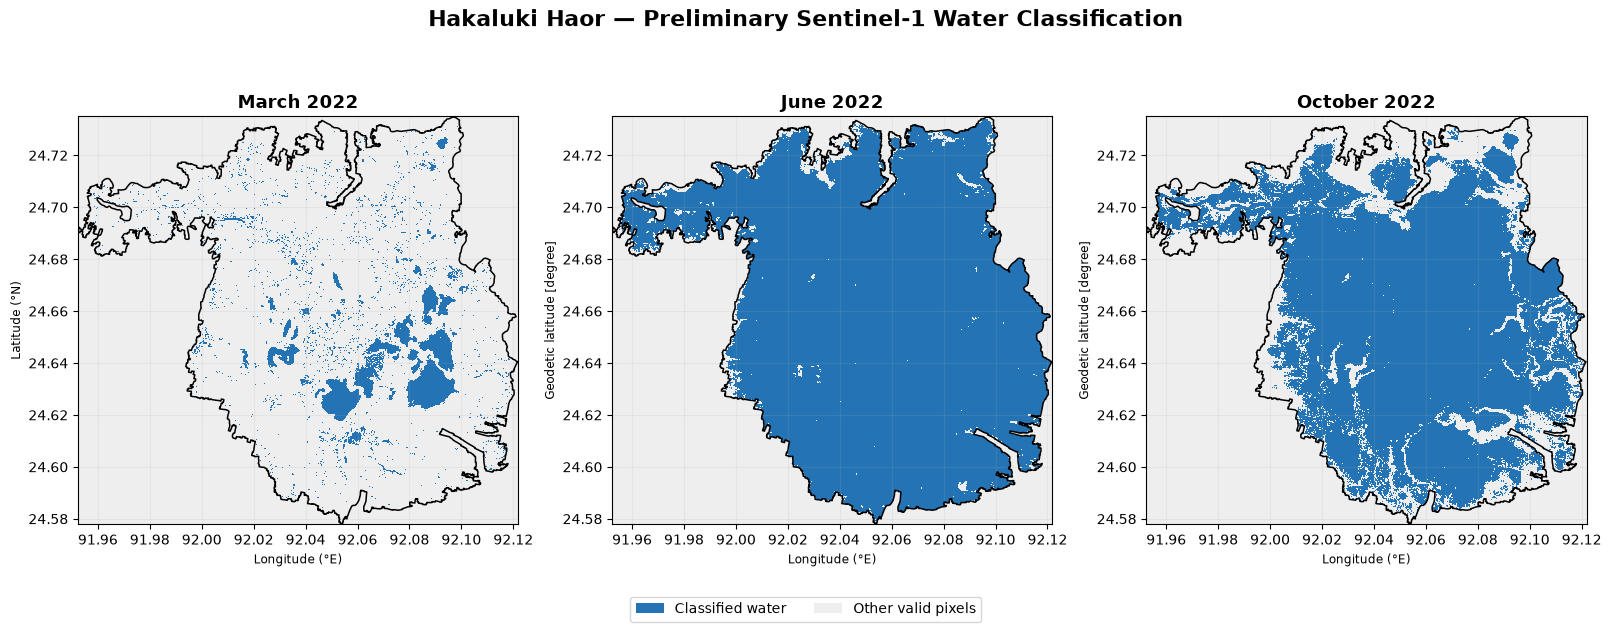

Maps saved to: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\maps\portfolio


In [3]:

from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import geopandas as gpd

ROOT = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

RASTERS = ROOT / "results" / "rasters"
OUTPUT = ROOT / "results" / "maps" / "portfolio"
OUTPUT.mkdir(parents=True, exist_ok=True)

BOUNDARY = (
    ROOT / "data" / "boundary" / "hakaluki_boundary.gpkg"
)

boundary = gpd.read_file(BOUNDARY)

months = {
    "March 2022": "03",
    "June 2022": "06",
    "October 2022": "10"
}

cmap = ListedColormap(["#eeeeee", "#2474b5"])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 6),
    constrained_layout=True
)

for ax, (month_name, month_code) in zip(
    axes, months.items()
):
    path = (
        RASTERS /
        f"HAKALUKI_2022_{month_code}_SAR_water.tif"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    with rasterio.open(path) as src:
        array = src.read(1, masked=True)

        # Retain only expected classification values
        valid = (
            (~np.ma.getmaskarray(array))
            & np.isin(np.ma.getdata(array), [0, 1])
        )

        data = np.ma.array(
            np.ma.getdata(array),
            mask=~valid
        )

        bounds = src.bounds
        extent = [
            bounds.left, bounds.right,
            bounds.bottom, bounds.top
        ]

        local_boundary = boundary.to_crs(src.crs)

    ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    local_boundary.boundary.plot(
        ax=ax,
        color="black",
        linewidth=1.1
    )

    ax.set_title(month_name, fontsize=13, weight="bold")
    ax.set_aspect("equal")
    ax.set_xlabel("Longitude (°E)")
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Latitude (°N)")

legend_elements = [
    Patch(facecolor="#2474b5", label="Classified water"),
    Patch(facecolor="#eeeeee", label="Other valid pixels")
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.04)
)

fig.suptitle(
    "Hakaluki Haor — Preliminary Sentinel-1 Water Classification",
    fontsize=16,
    weight="bold"
)

fig.savefig(
    OUTPUT / "Hakaluki_2022_SAR_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT / "Hakaluki_2022_SAR_Comparison.svg",
    bbox_inches="tight"
)

plt.show()

print("Maps saved to:", OUTPUT)


# 06 — Export reproducible research results, maps and a GitHub / portfolio gallery

Runs entirely **locally** after GEE results are saved to disk. No Earth Engine authentication is needed in this notebook. Does not simulate scientific observations. Missing maps or model outputs are listed as unavailable rather than invented.

## A. Inspect local files and build the release

In [4]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
ROOT = Path(r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project")
assert (ROOT / 'config' / 'settings.json').exists(), f"Wrong project folder: {ROOT}"
sys.path.insert(0, str(ROOT))
from src.portfolio_export import build_release
REPORT = build_release(ROOT, include_rasters=False)
print('Release completed:')
for k,v in REPORT.items():print(f'  {k}: {v}')
RELEASE = ROOT / 'results' / 'github_release'


Release completed:
  release_dir: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\github_release
  n_months: 84
  years: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
  n_tifs: 18
  n_figures_png: 24
  n_release_files: 142


## B. Preview portfolio images generated from actual data

PNG figures: 24
01_monthly_timeseries.png


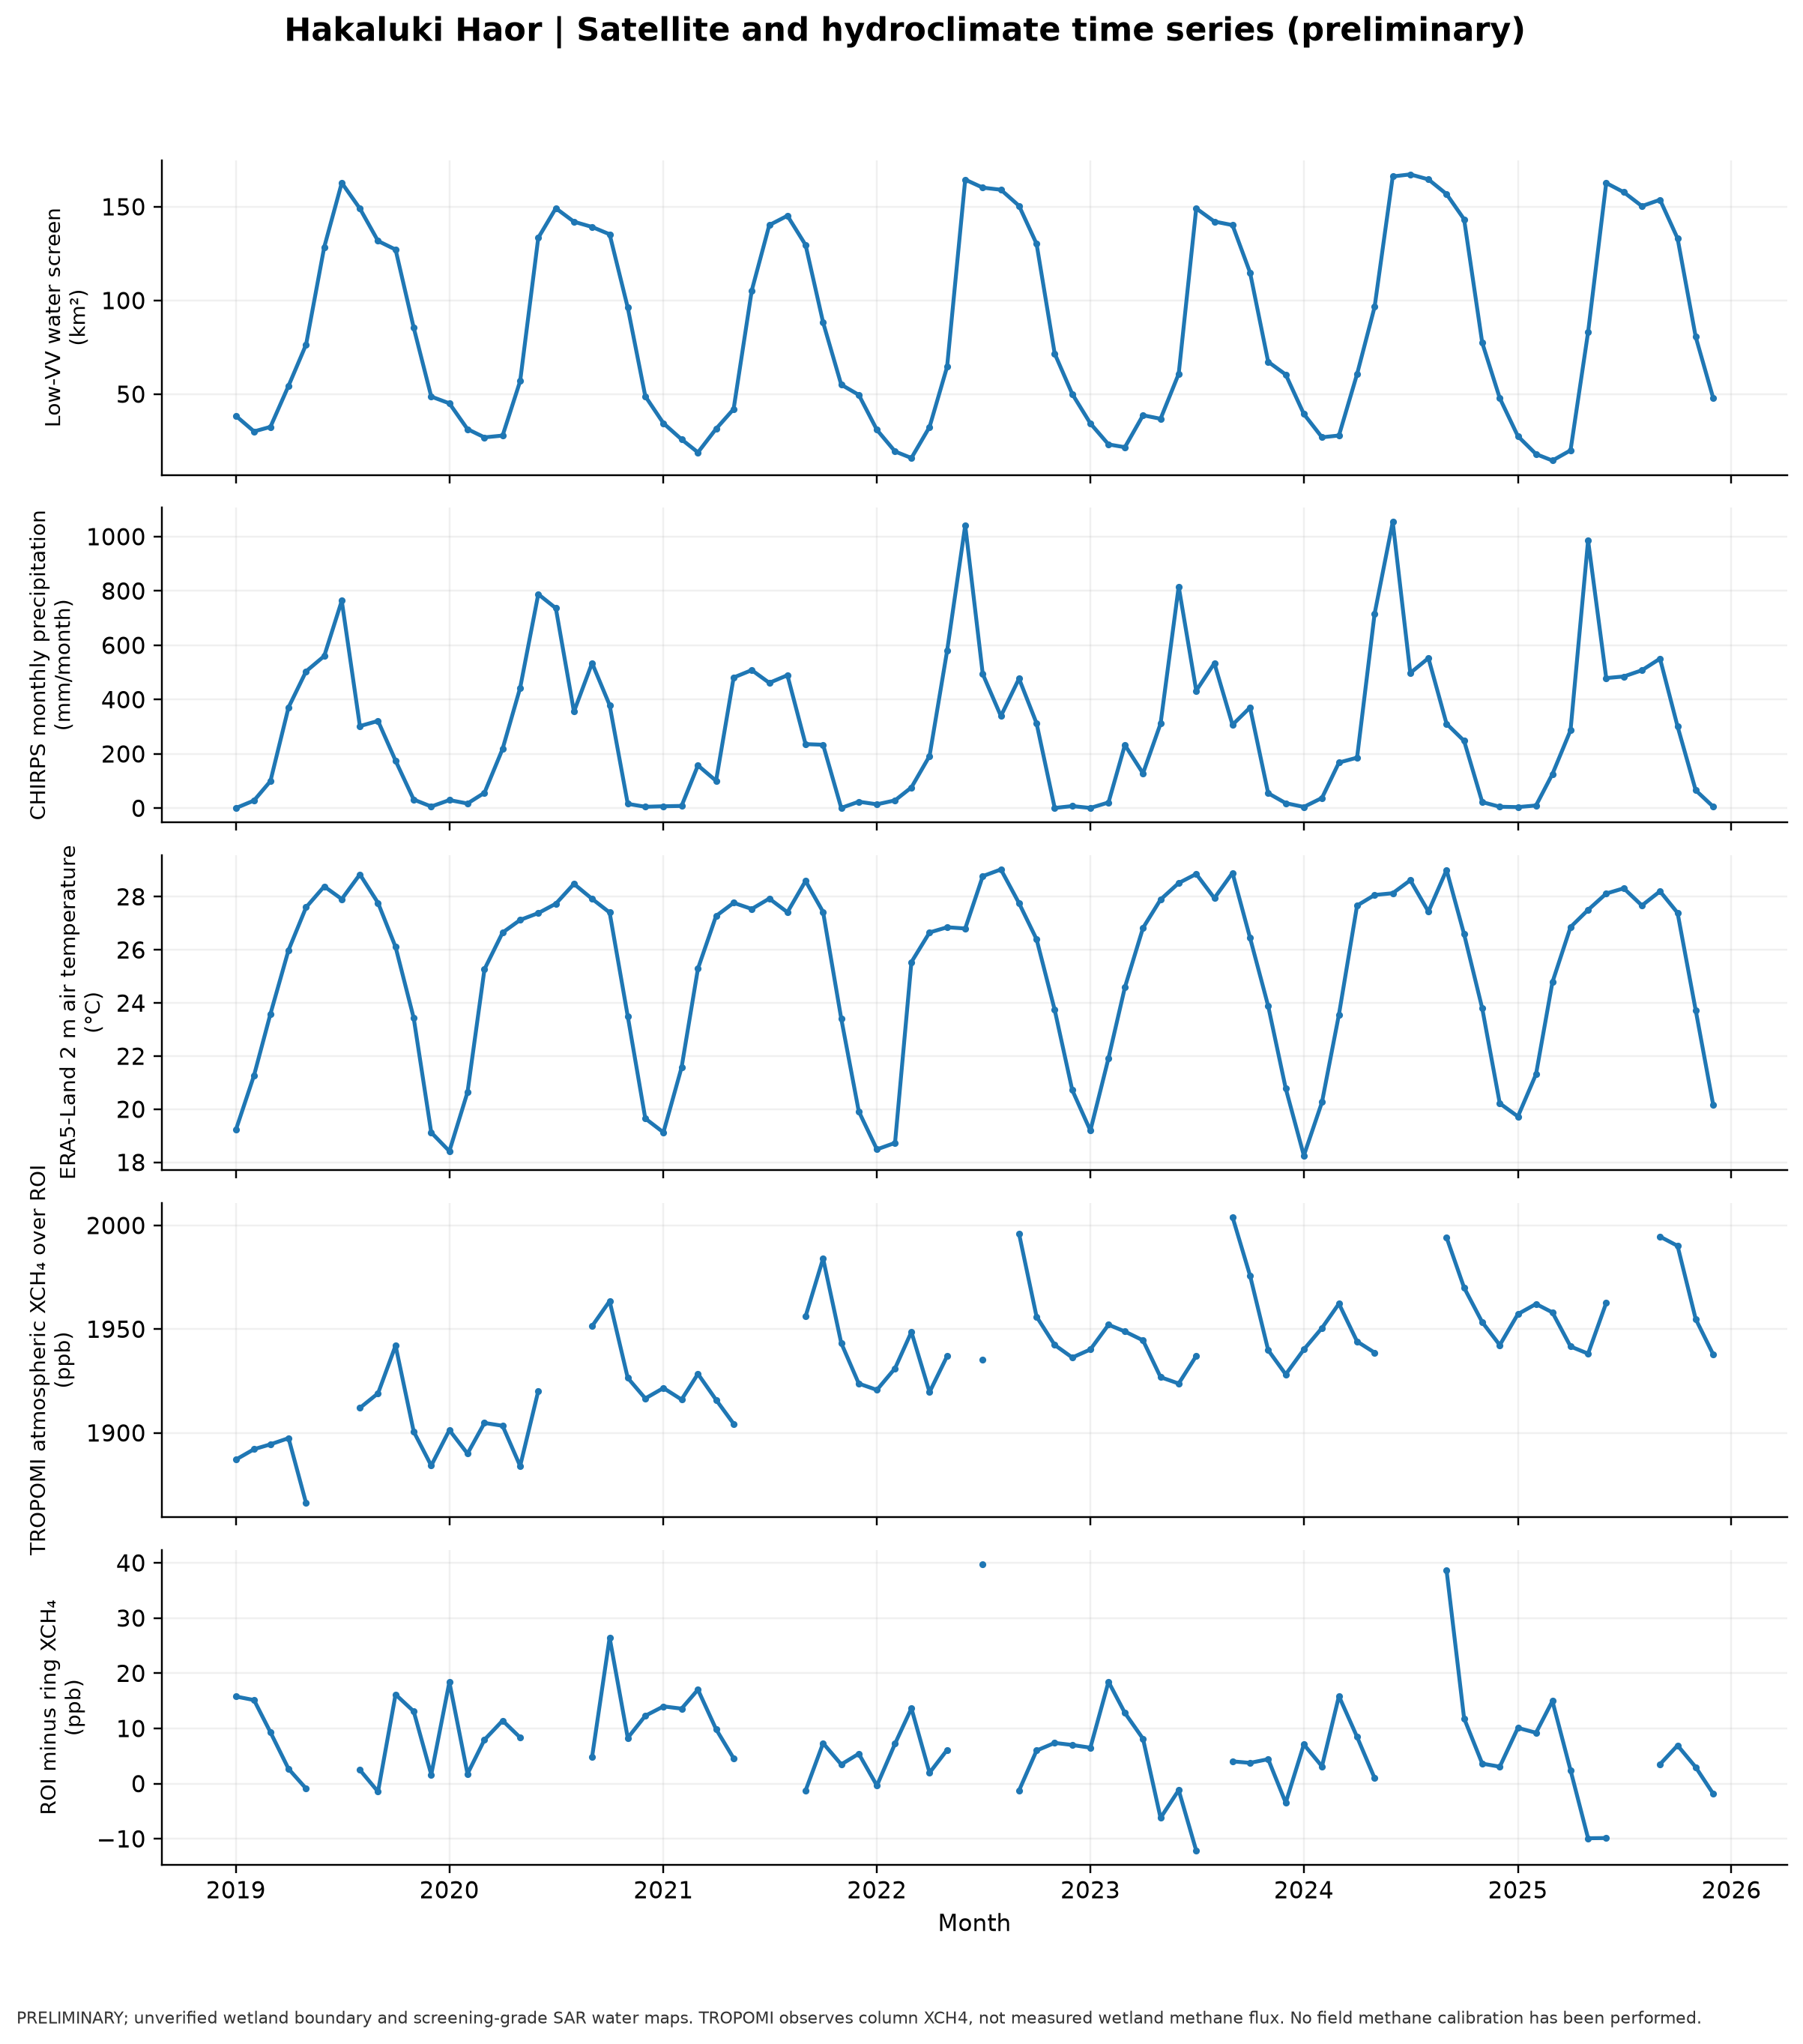

02_data_completeness.png


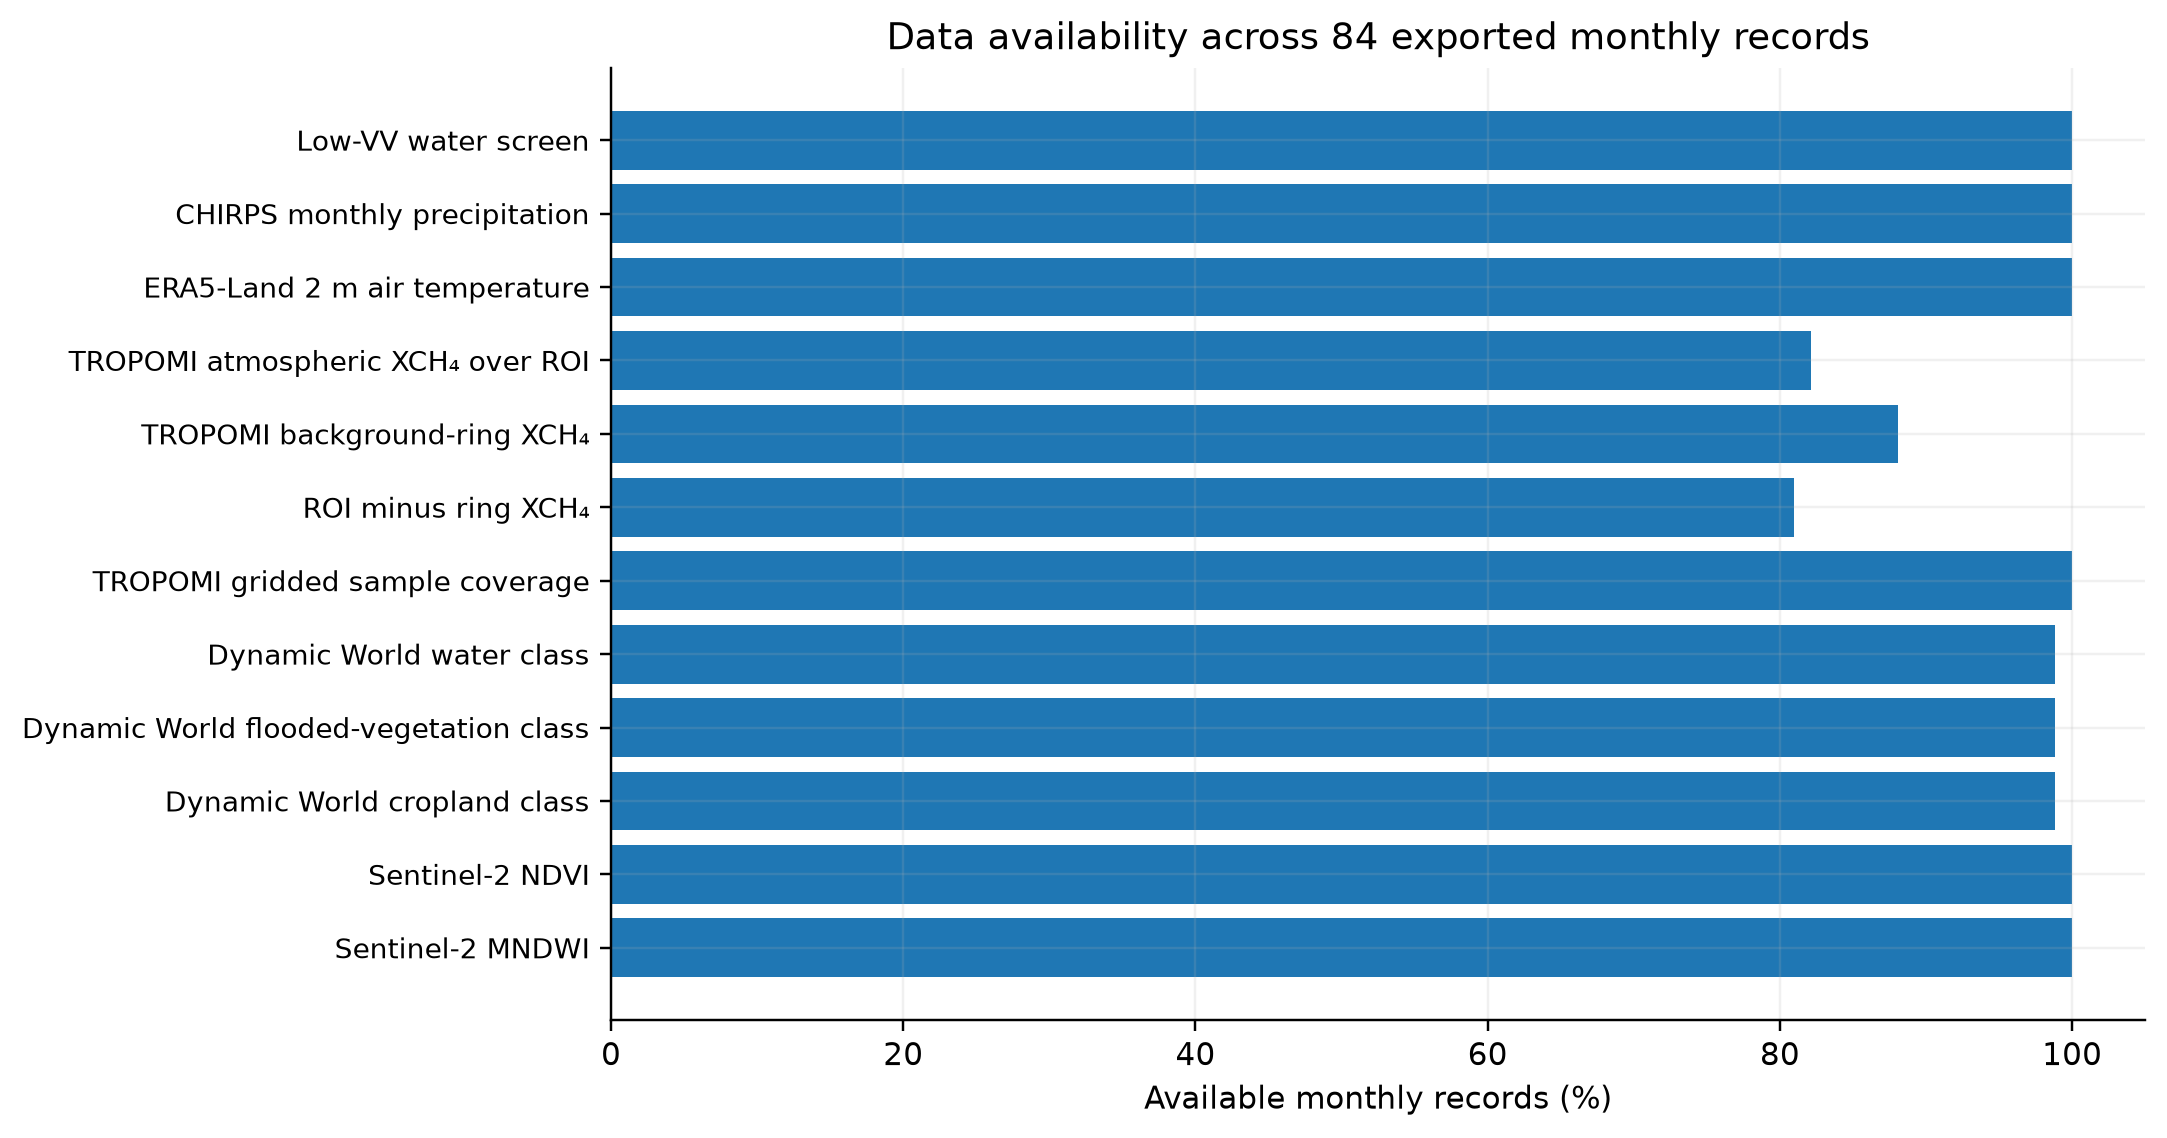

03_monthly_seasonality.png


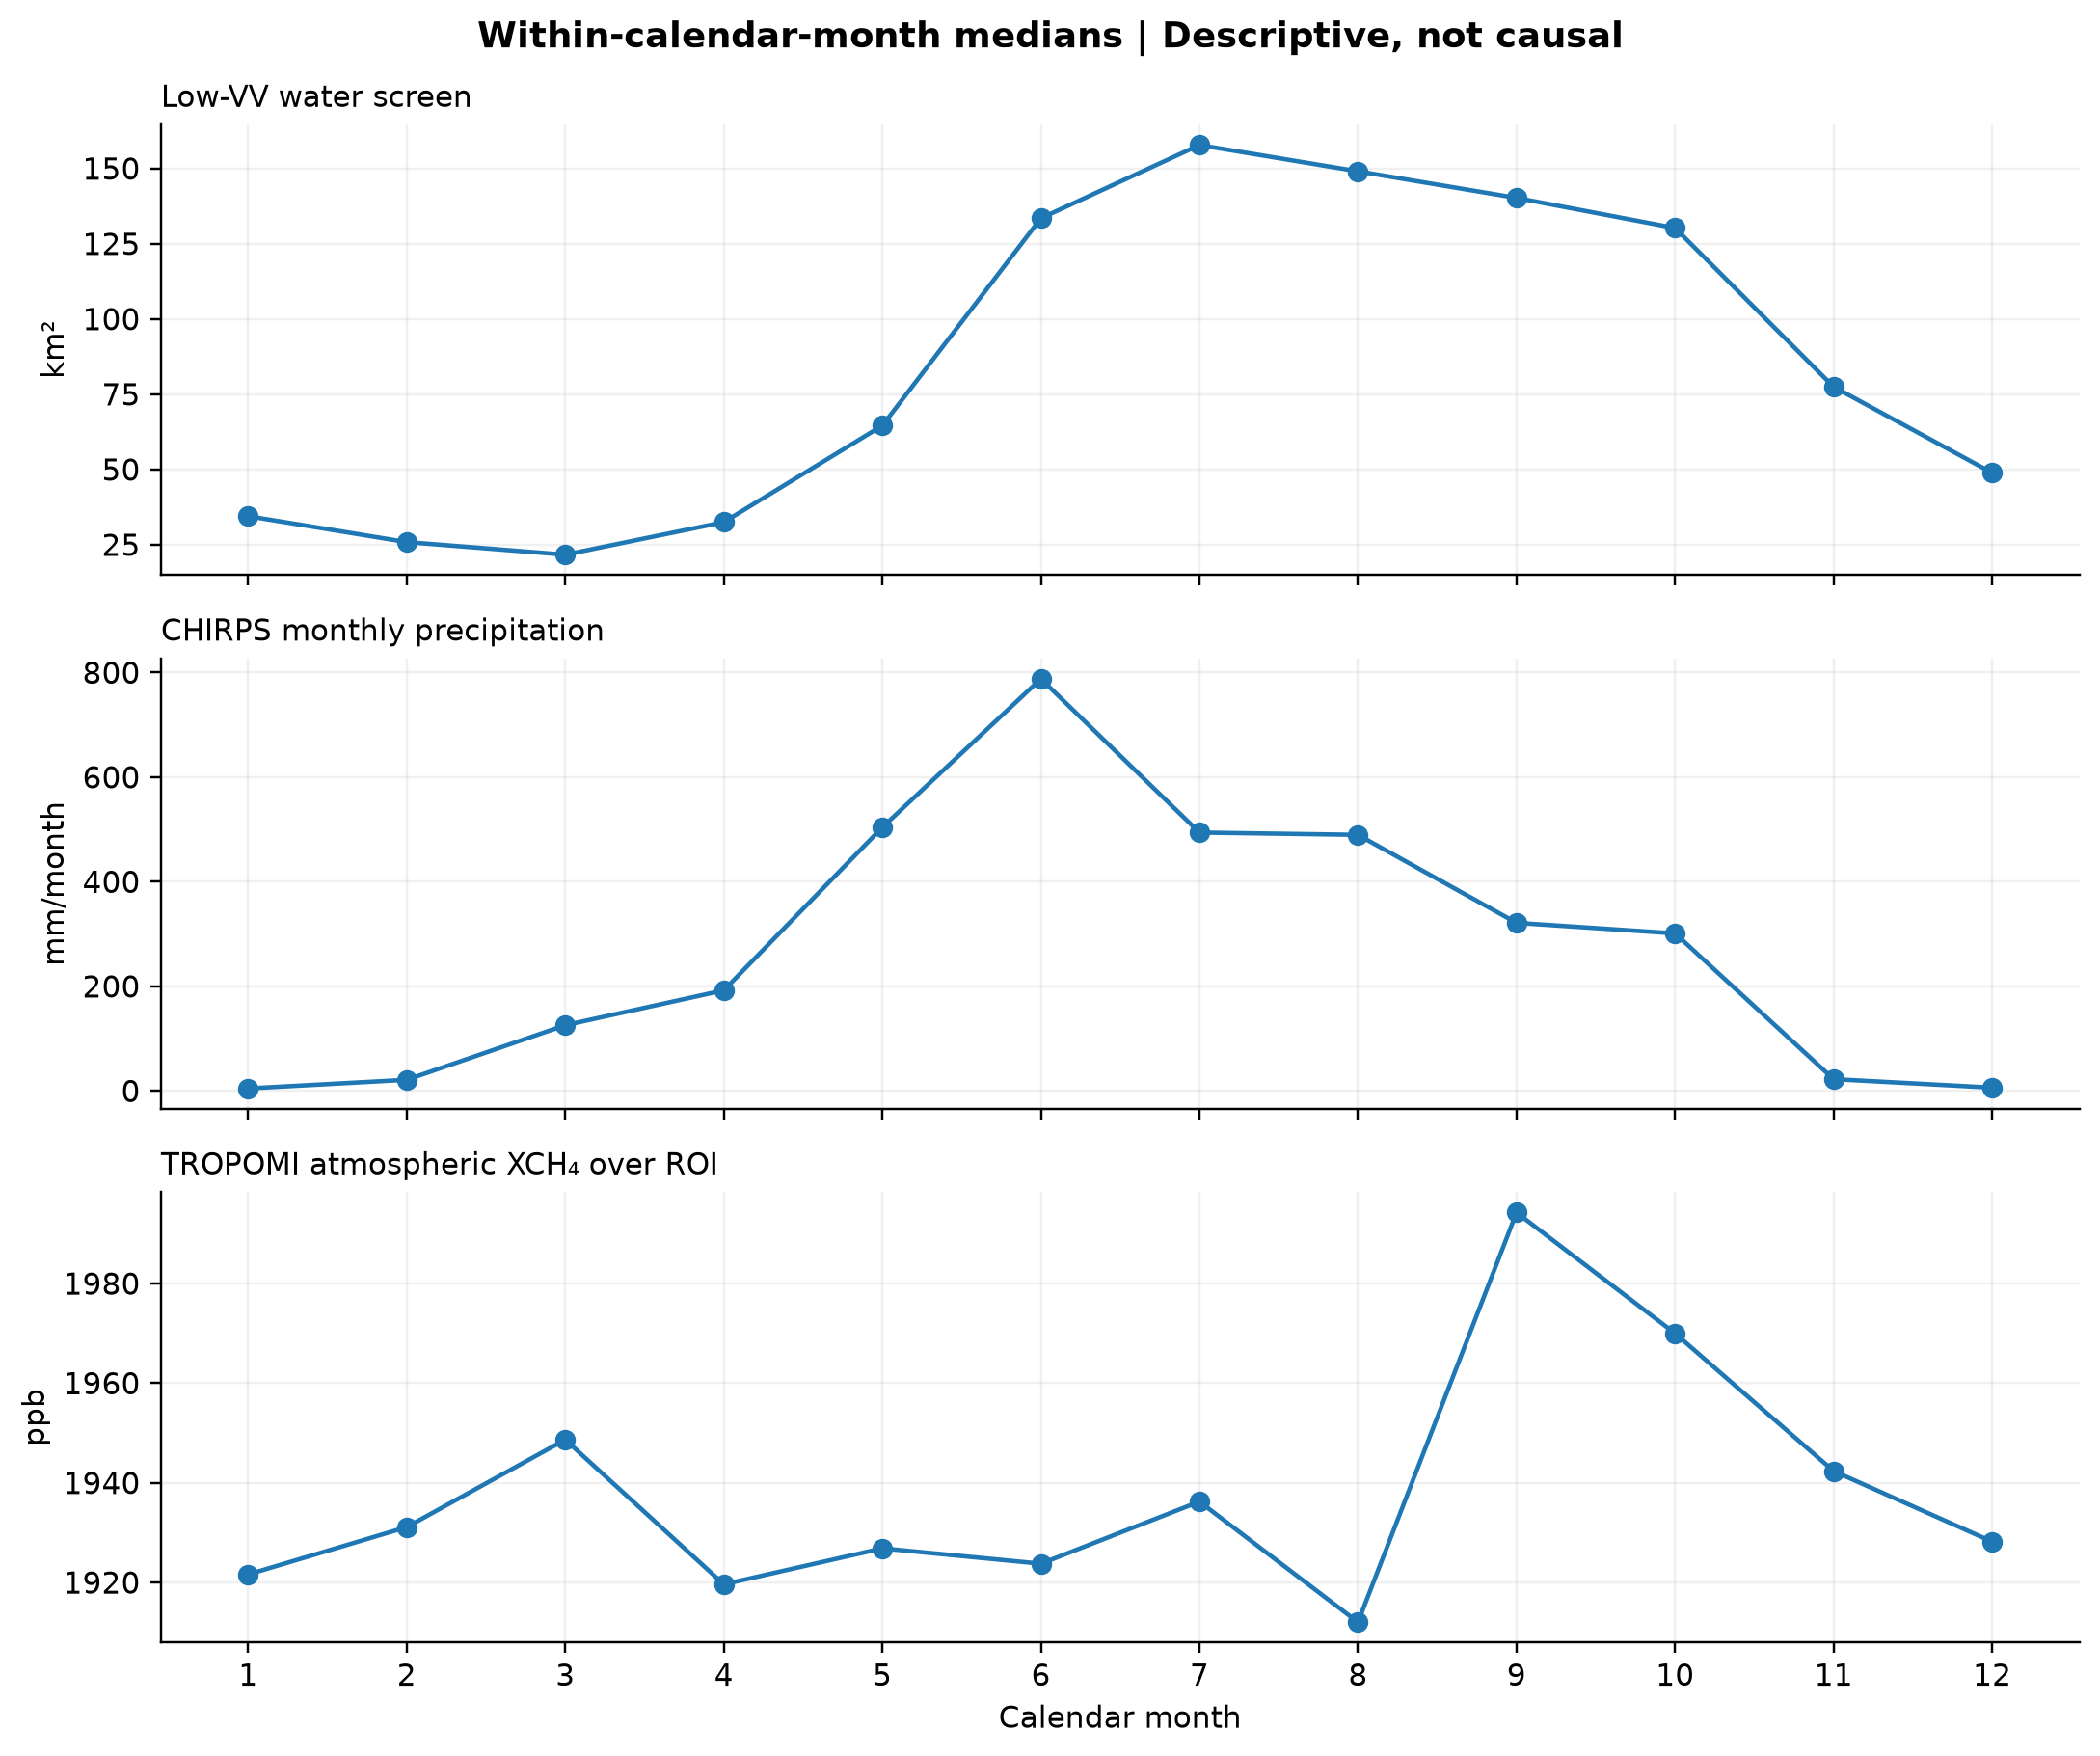

04_exploratory_correlations.png


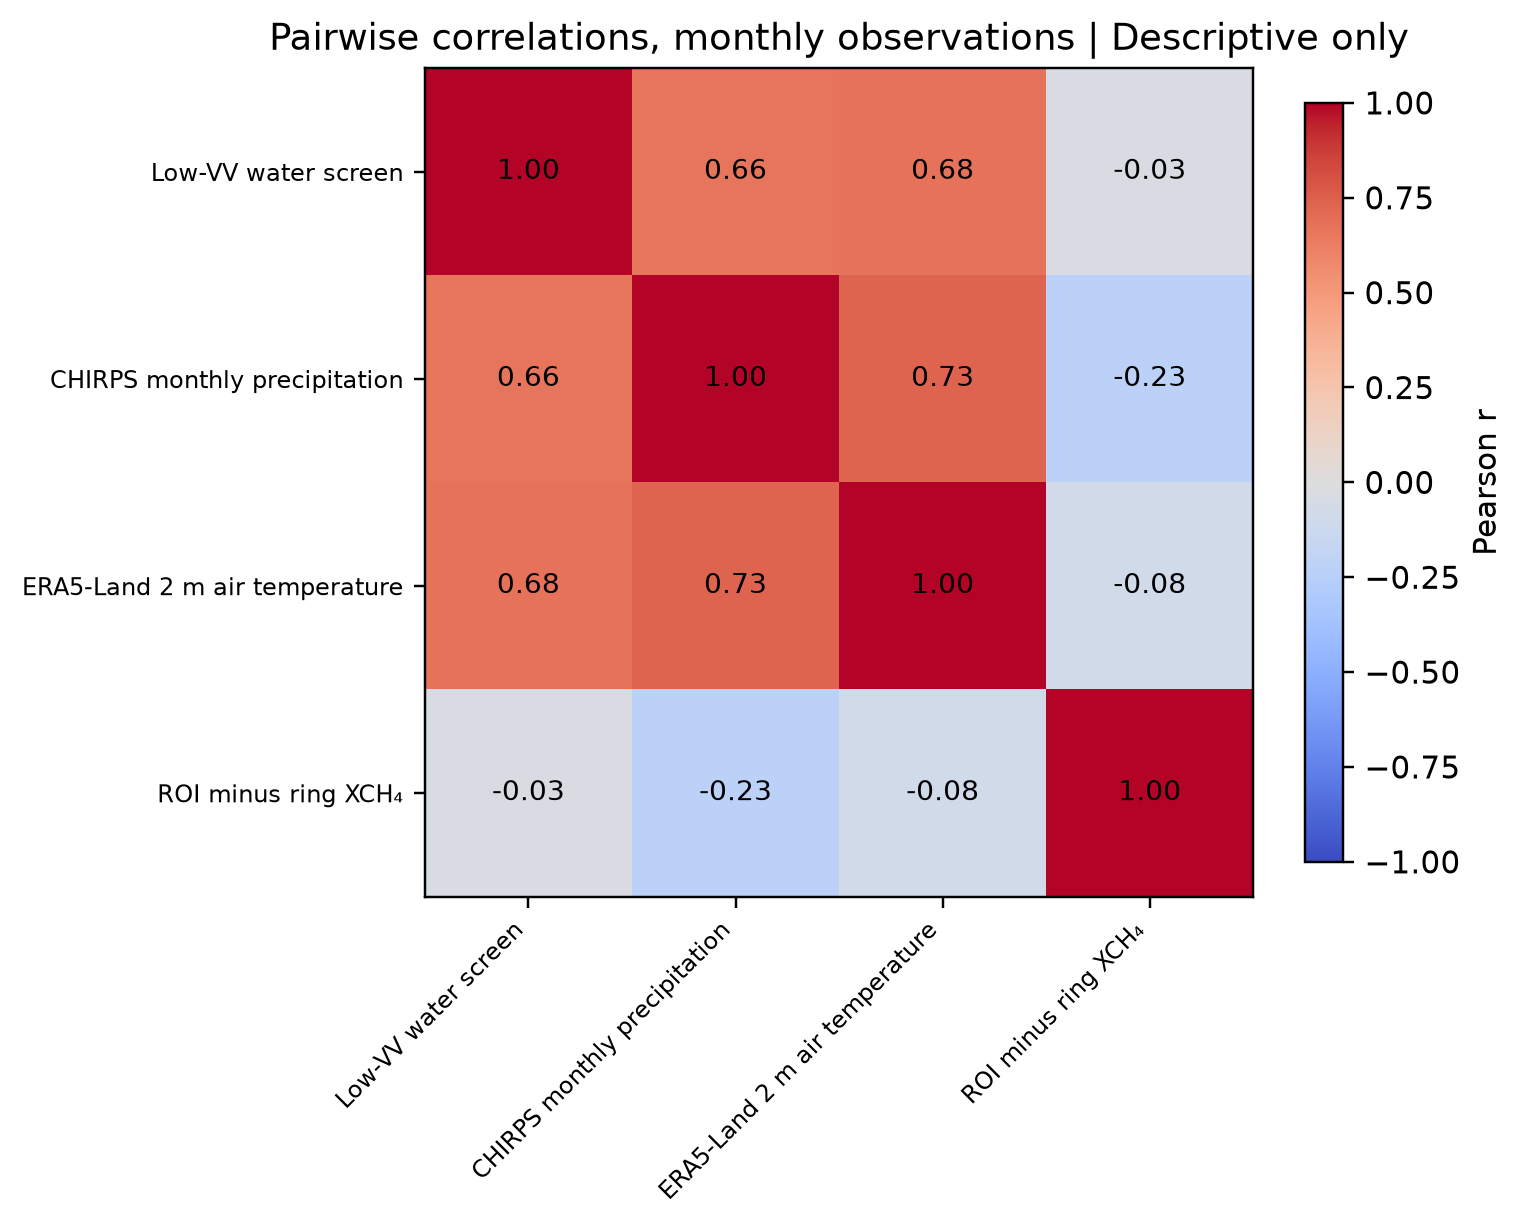

boundary_QA_00_reference_extent_NOT_WETLAND_BOUNDARY.png


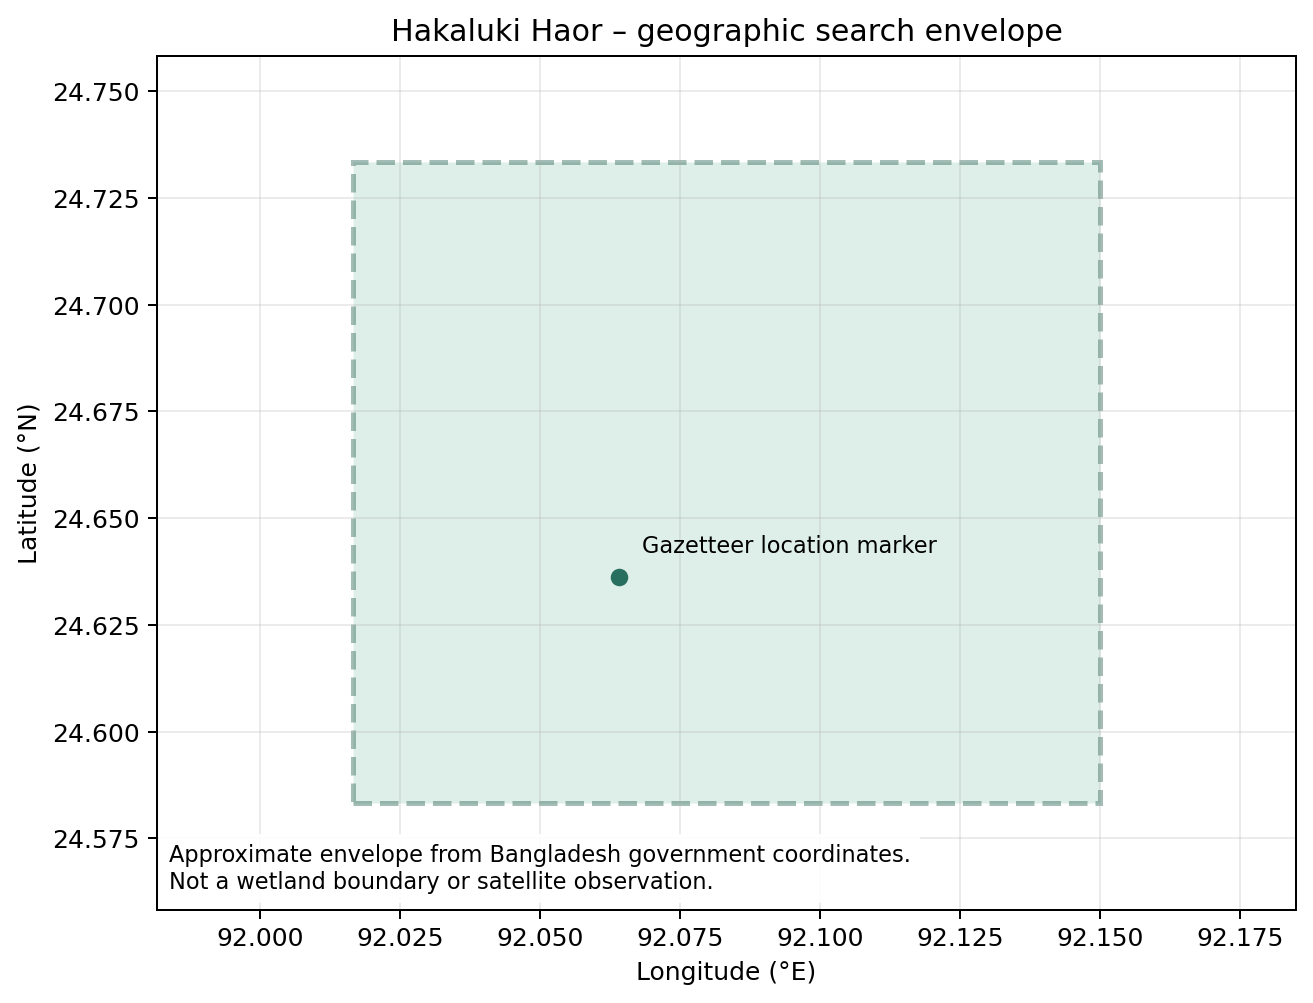

boundary_QA_01_boundary_audit_candidate.png


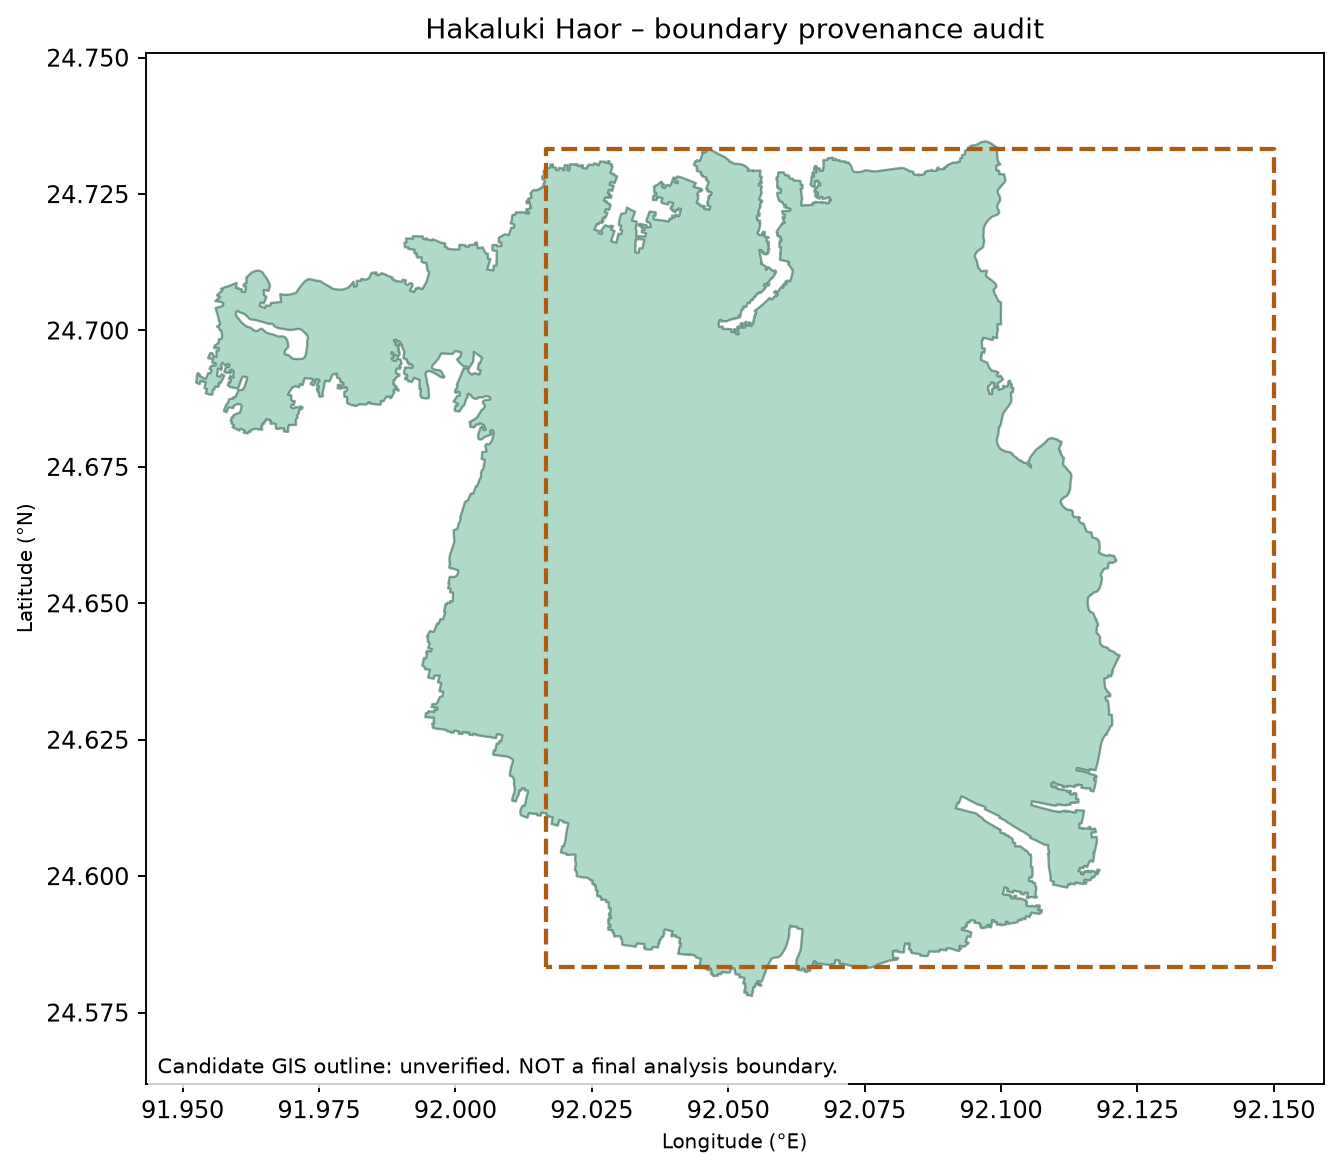

map_HAKALUKI_2022_03_CHIRPS_rain.png


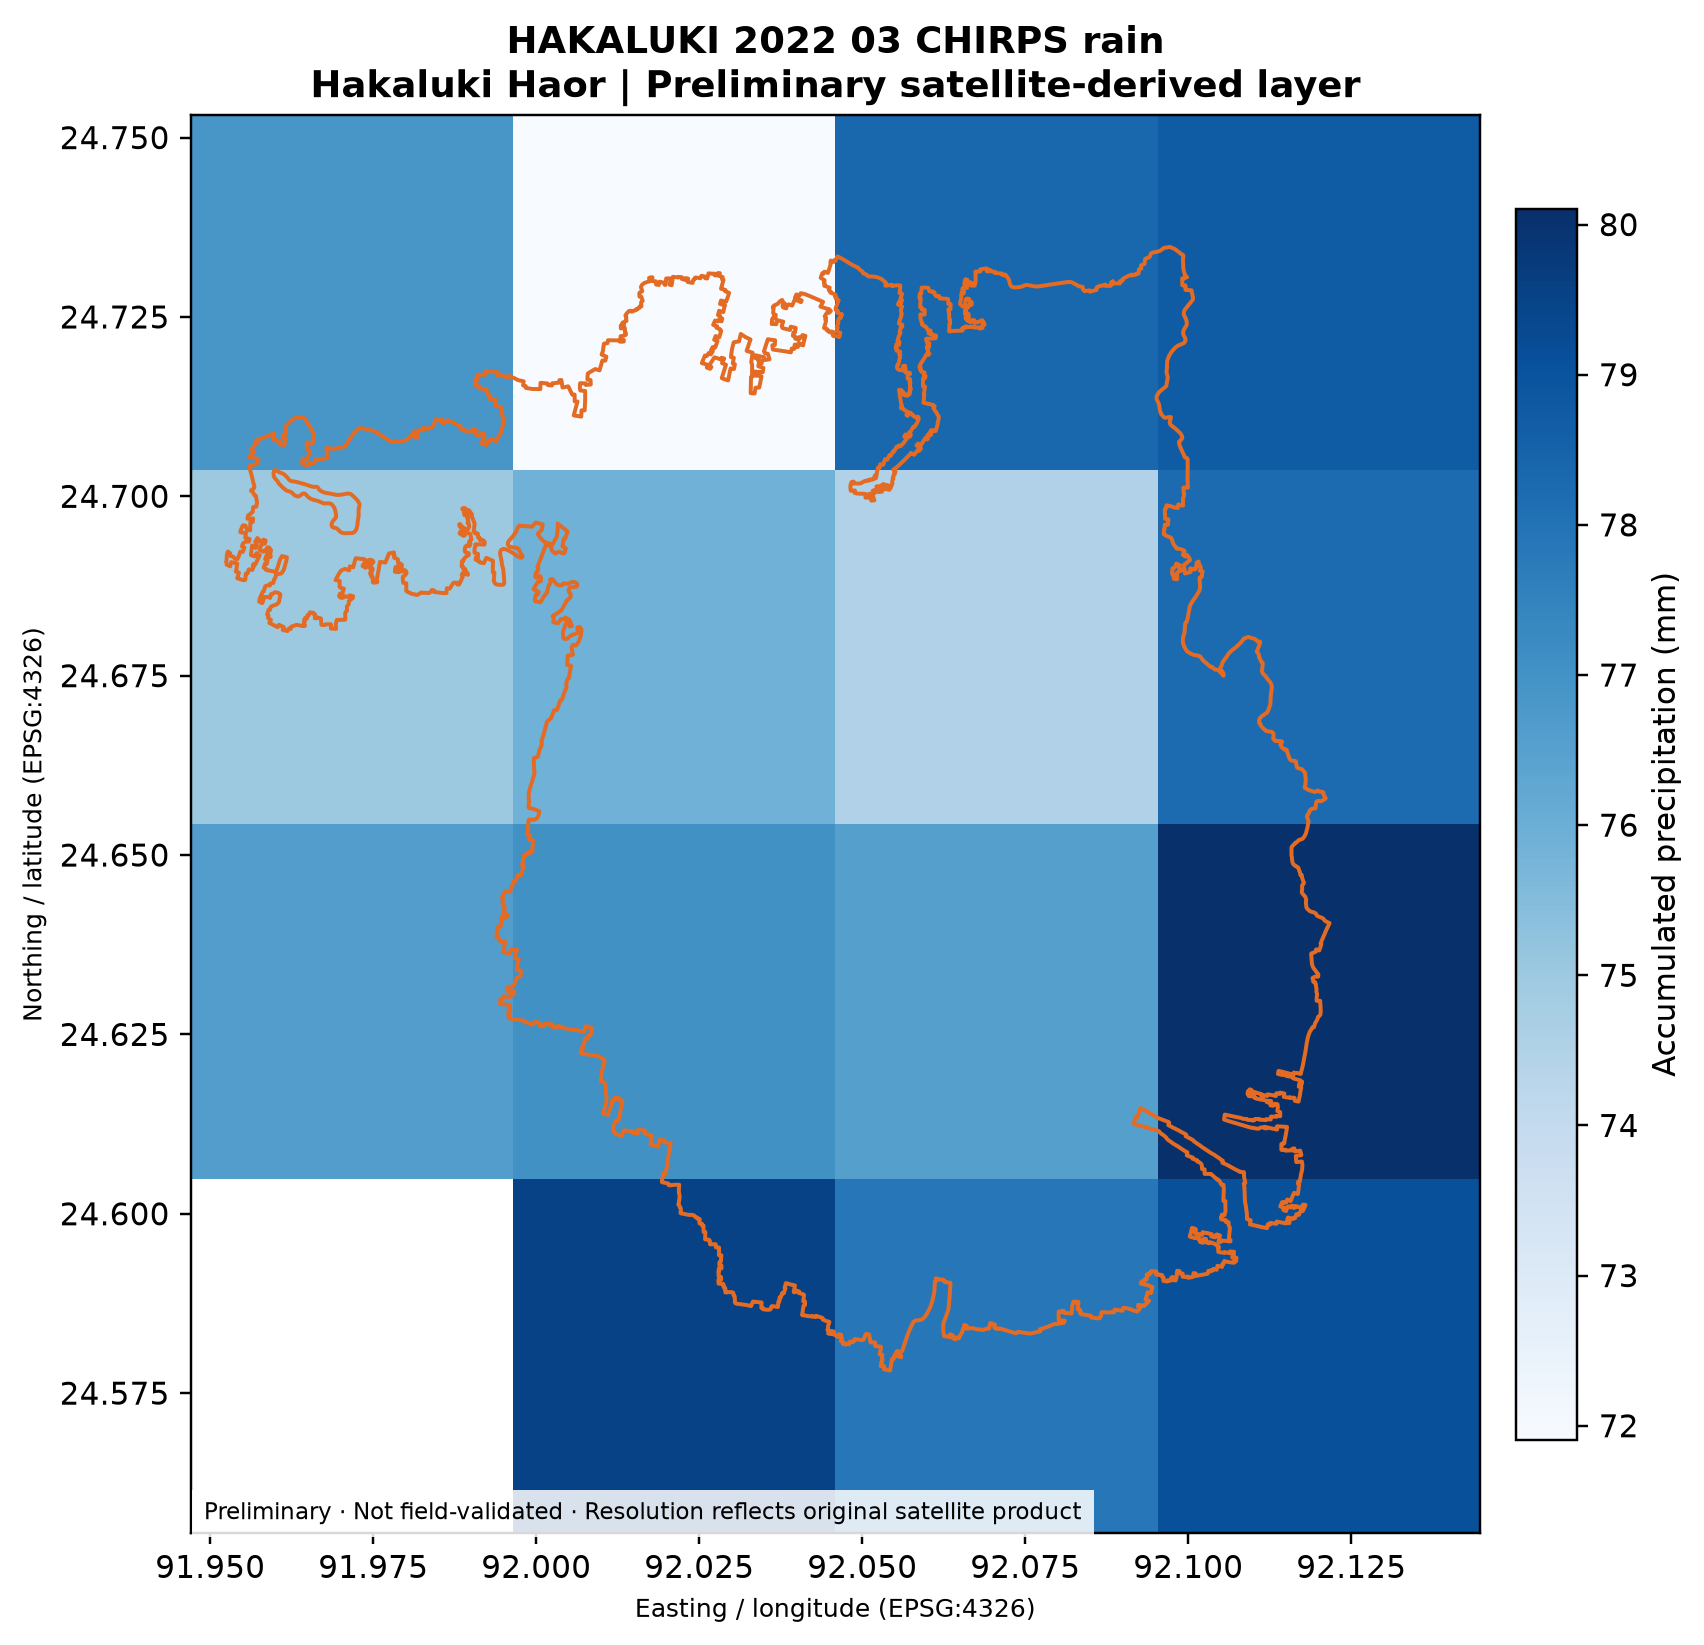

map_HAKALUKI_2022_03_DW_class.png


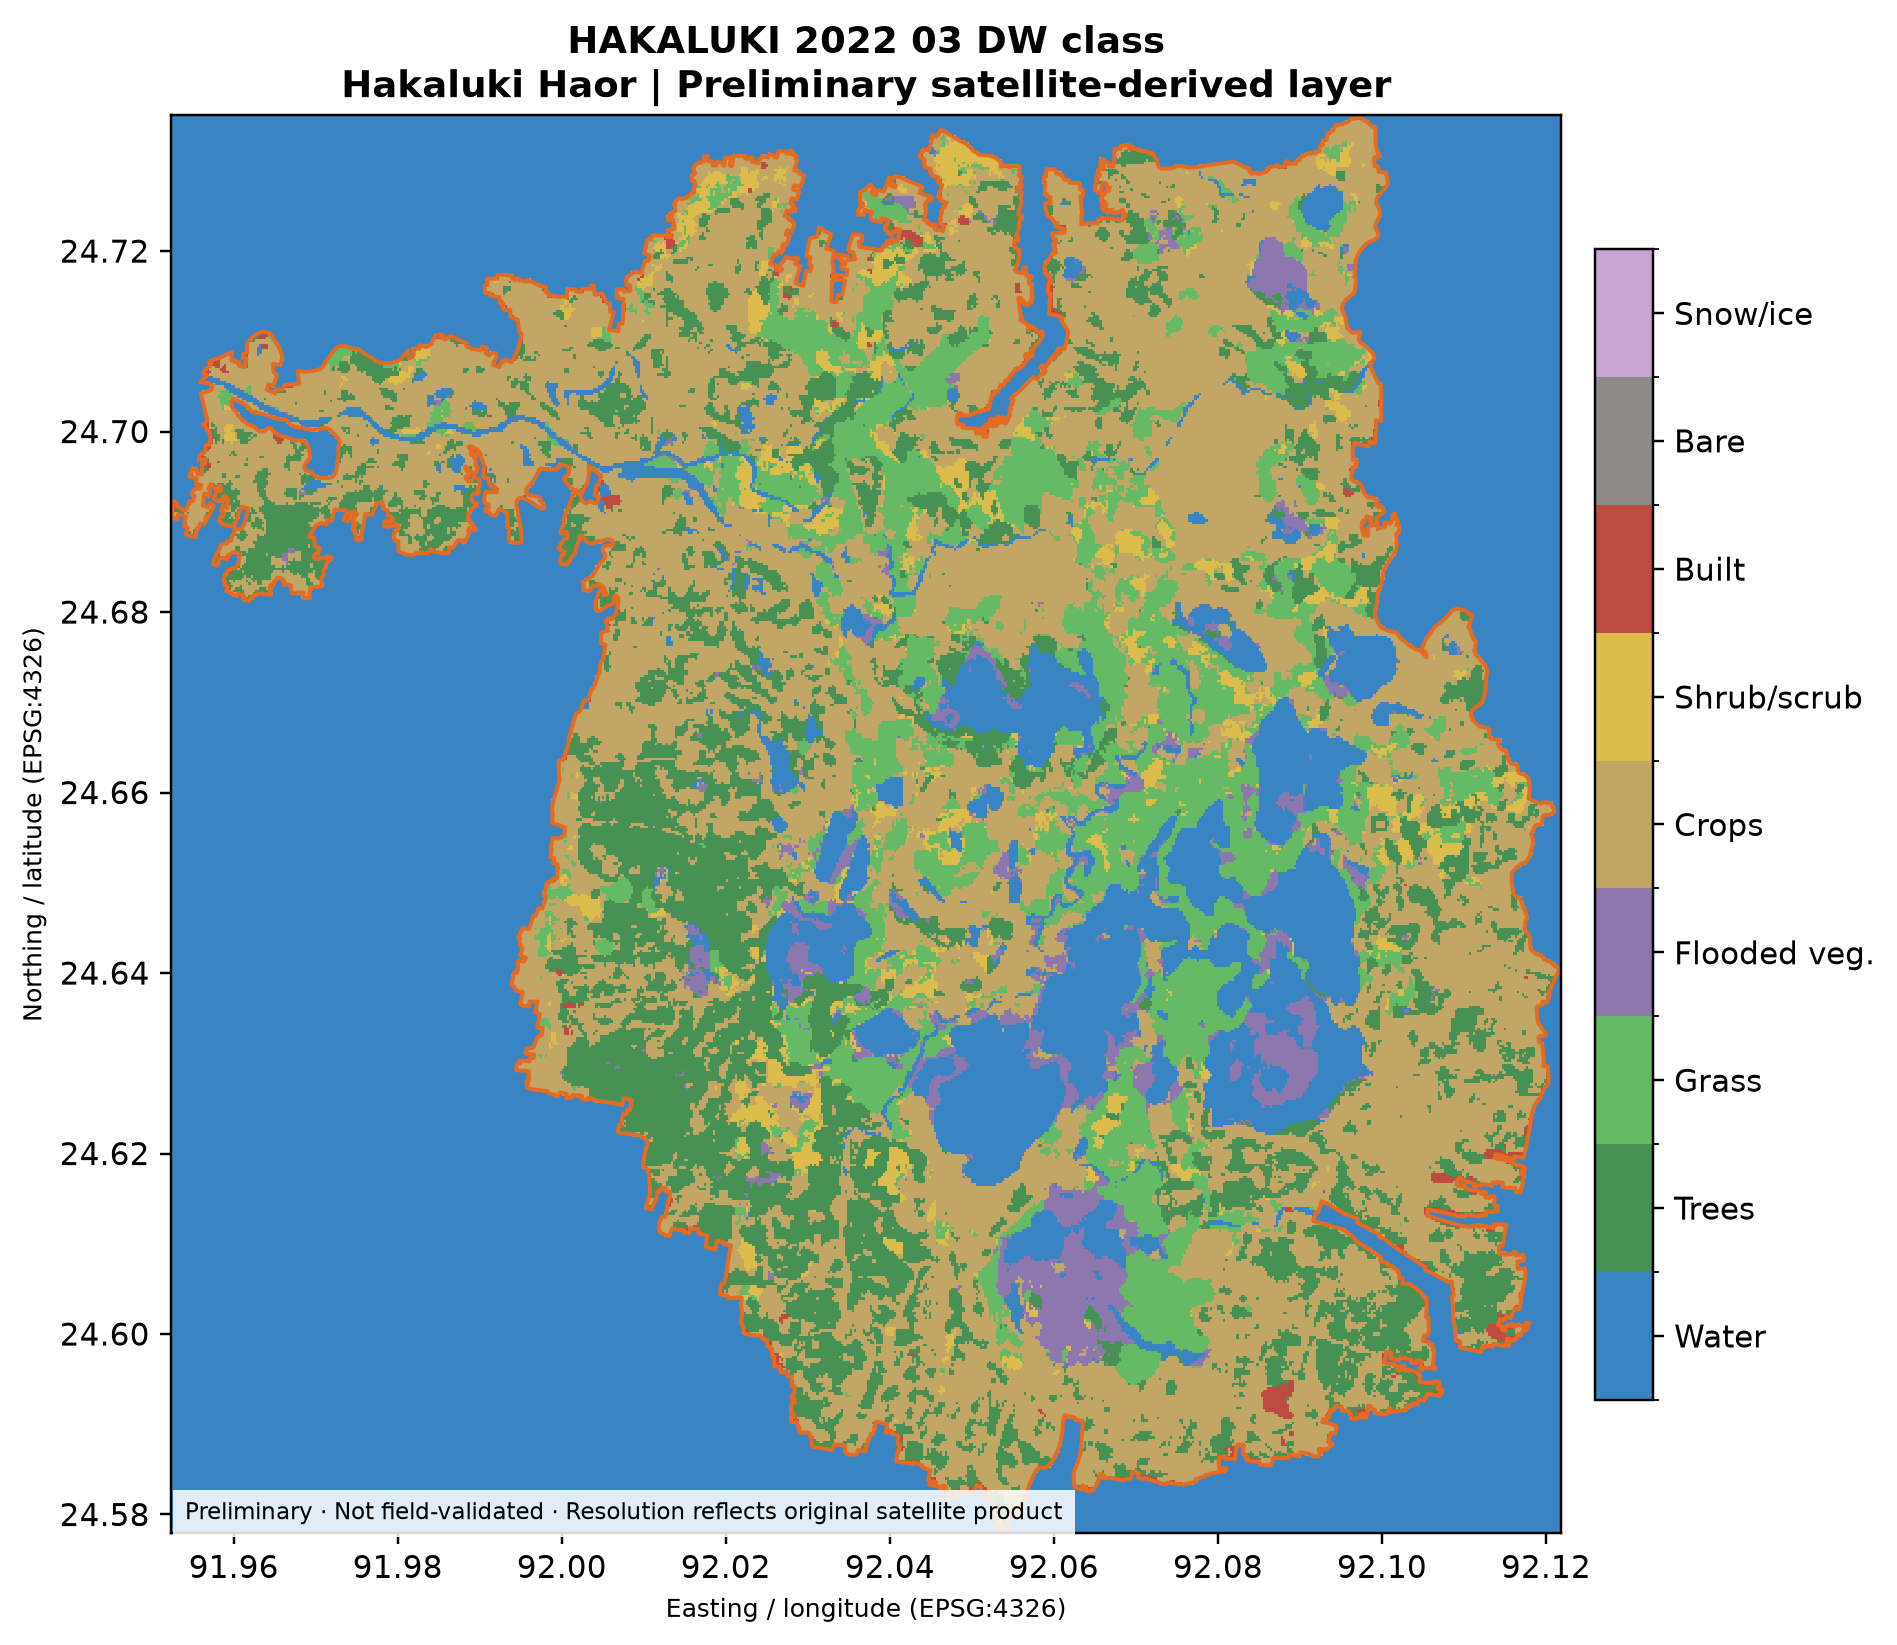

In [5]:
pngs = sorted((RELEASE / 'figures').glob('*.png'))
print('PNG figures:',len(pngs))
if pngs:
    for p in pngs[:8]:
        print(p.name)
        display(Image(filename=str(p),width=750))
else:
    print('No real figures yet. Run Notebooks 01/02 and download completed GeoTIFFs.')


## C. Check exported CSV tables and geospatial raster catalog

In [6]:
import pandas as pd
csvs=sorted((RELEASE/'data').glob('*.csv'))
print('CSV tables:',len(csvs))
for p in csvs[:20]:
    print(' -',p.name,':',p.stat().st_size,'bytes')
manifest = pd.read_csv(RELEASE/'data'/'raster_catalog.csv')
display(manifest.head(20))


CSV tables: 108
 - CHIRPS_daily_2022.csv : 12888 bytes
 - complete_data_quality_2019_2025.csv : 827 bytes
 - data_completeness.csv : 534 bytes
 - ee_export_task_manifest.csv : 4346 bytes
 - exploratory_year_holdout_models.csv : 227 bytes
 - field_flux_template_NOT_OBSERVATIONS.csv : 225 bytes
 - hakaluki_2019_2025_data_quality.csv : 245 bytes
 - hakaluki_2022_daily_CHIRPS_rainfall.csv : 8556 bytes
 - hakaluki_2022_pilot_quality_audit.csv : 6157 bytes
 - hakaluki_monthly_2019_2025.csv : 36170 bytes
 - hakaluki_pilot_2022_monthly.csv : 5617 bytes
 - missingness_by_variable.csv : 169 bytes
 - monthly_2019-01.csv : 910 bytes
 - monthly_2019-02.csv : 912 bytes
 - monthly_2019-03.csv : 907 bytes
 - monthly_2019-04.csv : 905 bytes
 - monthly_2019-05.csv : 912 bytes
 - monthly_2019-06.csv : 841 bytes
 - monthly_2019-07.csv : 840 bytes
 - monthly_2019-08.csv : 912 bytes


,band_count,crs,height_pixels,map_file,nodata,note,pixel_size_x,pixel_size_y,preview_max,preview_min,raster,rendered,source_local_path,width_pixels
0,1,EPSG:4326,4,figures\map_HAKALUKI_2022_03_CHIRPS_rain.png,NaN,"statistics from downsampled preview, not indep...",0.049407,0.049407,80.101807,71.907745,HAKALUKI_2022_03_CHIRPS_rain.tif,True,results\rasters\HAKALUKI_2022_03_CHIRPS_rain.tif,4
1,1,EPSG:4326,583,figures\map_HAKALUKI_2022_03_DW_class.png,NaN,"statistics from downsampled preview, not indep...",0.000269,0.000269,7.000000,0.000000,HAKALUKI_2022_03_DW_class.tif,True,results\rasters\HAKALUKI_2022_03_DW_class.tif,629
2,1,EPSG:4326,3,figures\map_HAKALUKI_2022_03_ERA5_temp.png,NaN,"statistics from downsampled preview, not indep...",0.098815,0.098815,25.918447,24.743830,HAKALUKI_2022_03_ERA5_temp.tif,True,results\rasters\HAKALUKI_2022_03_ERA5_temp.tif,3
3,1,EPSG:4326,873,figures\map_HAKALUKI_2022_03_S2_MNDWI.png,NaN,"statistics from downsampled preview, not indep...",0.000180,0.000180,0.775027,-0.685441,HAKALUKI_2022_03_S2_MNDWI.tif,True,results\rasters\HAKALUKI_2022_03_S2_MNDWI.tif,943
4,1,EPSG:4326,873,figures\map_HAKALUKI_2022_03_S2_NDVI.png,NaN,"statistics from downsampled preview, not indep...",0.000180,0.000180,0.872223,-0.375000,HAKALUKI_2022_03_S2_NDVI.tif,True,results\rasters\HAKALUKI_2022_03_S2_NDVI.tif,943
5,1,EPSG:4326,583,figures\map_HAKALUKI_2022_03_SAR_water.png,NaN,"statistics from downsampled preview, not indep...",0.000269,0.000269,1.000000,0.000000,HAKALUKI_2022_03_SAR_water.tif,True,results\rasters\HAKALUKI_2022_03_SAR_water.tif,629
6,1,EPSG:4326,4,figures\map_HAKALUKI_2022_06_CHIRPS_rain.png,NaN,"statistics from downsampled preview, not indep...",0.049407,0.049407,1149.051025,938.462280,HAKALUKI_2022_06_CHIRPS_rain.tif,True,results\rasters\HAKALUKI_2022_06_CHIRPS_rain.tif,4
7,1,EPSG:4326,583,figures\map_HAKALUKI_2022_06_DW_class.png,NaN,"statistics from downsampled preview, not indep...",0.000269,0.000269,8.000000,0.000000,HAKALUKI_2022_06_DW_class.tif,True,results\rasters\HAKALUKI_2022_06_DW_class.tif,629
8,1,EPSG:4326,3,figures\map_HAKALUKI_2022_06_ERA5_temp.png,NaN,"statistics from downsampled preview, not indep...",0.098815,0.098815,26.880209,26.400204,HAKALUKI_2022_06_ERA5_temp.tif,True,results\rasters\HAKALUKI_2022_06_ERA5_temp.tif,3
9,1,EPSG:4326,873,figures\map_HAKALUKI_2022_06_S2_MNDWI.png,NaN,"statistics from downsampled preview, not indep...",0.000180,0.000180,0.876000,-1.000000,HAKALUKI_2022_06_S2_MNDWI.tif,True,results\rasters\HAKALUKI_2022_06_S2_MNDWI.tif,943


## D. Open the GitHub Pages gallery or upload the GitHub release directory

In [7]:
import webbrowser
print('Open this HTML file in your browser:')
print(RELEASE / 'index.html')
print('For GitHub, upload the CONTENTS of:', RELEASE)
# Run this manually if desired:
# webbrowser.open((RELEASE / 'index.html').as_uri())


Open this HTML file in your browser:
F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\github_release\index.html
For GitHub, upload the CONTENTS of: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\results\github_release


## E. Scientific limits and later field calibration

The user-supplied wetland boundary remains unverified. These maps are exploratory. A monthly SAR water screen cannot establish precisely dated flash-flood initiation or flooding below dense vegetation. Atmospheric methane XCH₄ is not wetland methane flux, and simple reference-ring anomalies are not inversion-based emission estimates. **Field methane calibration is still planned** and should be added later to the independent flux modelling component.

Read `GITHUB_EXPORT_GUIDE.md` before putting any datasets on a public repository; respect their attribution and licenses.
